#Proyecto final-Redes Neuronales

Docente: Oscar Andrés Arias M

- Ana María Amador

- Daniela López Rincón

##Fase A: Análisis Exploratorio y Prototipado

###Instalación de Eigen y verificación del entorno C++

In [ ]:
%%bash
# Se actualiza el índice de paquetes y se instala Eigen (biblioteca de álgebra lineal
# para C++ que solo requiere cabeceras, por lo que no necesita enlazado de librerías).
apt-get -qq update
apt-get -qq install -y libeigen3-dev > /dev/null

# Se verifica la versión del compilador y la versión de Eigen instalada.
g++ --version | head -n 1
grep -E "define EIGEN_(WORLD|MAJOR|MINOR)_VERSION" /usr/include/eigen3/Eigen/src/Core/util/Macros.h

g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
#define EIGEN_WORLD_VERSION 3
#define EIGEN_MAJOR_VERSION 4
#define EIGEN_MINOR_VERSION 0


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


###Importación de bibliotecas y definición de parámetros globales

In [ ]:

# Se importan las bibliotecas necesarias para la gestión de datos,
# ejecución de procesos, operaciones matemáticas, visualización
# y construcción y evaluación del modelo de regresión logística.

import os, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Se importa el modelo de regresión logística de Scikit-Learn,
# junto con las métricas que permitirán evaluar su rendimiento.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Se seleccionan las dos clases de imágenes del conjunto de datos MNIST
# que se utilizarán para realizar una clasificación binaria.
# La clase negativa corresponde al dígito 3 y se representa con 0.
# La clase positiva corresponde al dígito 8 y se representa con 1.
CLASE_NEG = 3
CLASE_POS = 8

# Se establecen los hiperparámetros que controlarán el entrenamiento
# de los modelos. Estos valores se mantienen constantes entre las
# implementaciones para garantizar condiciones de comparación equivalentes.
LR      = 0.1     # Tasa de aprendizaje utilizada para actualizar los pesos.
EPOCAS  = 1000    # Número de iteraciones de entrenamiento con gradiente descendente batch.
LAMBDA  = 1e-4    # Coeficiente de regularización L2 para controlar los valores de los pesos.

# Se establece una semilla aleatoria para garantizar que los procesos
# que utilizan números aleatorios puedan reproducirse en distintas ejecuciones.
SEMILLA = 42
np.random.seed(SEMILLA)

# Se configura el estilo visual de Seaborn para obtener gráficos
# con cuadrícula y una presentación uniforme durante el análisis exploratorio.
sns.set_theme(style="whitegrid")


Se establecen las herramientas y los parámetros iniciales necesarios para desarrollar el proceso de clasificación binaria de imágenes MNIST. Se seleccionan los dígitos 3 y 8 como categorías de estudio, se definen los hiperparámetros que controlarán el entrenamiento y se configura la reproducibilidad de los experimentos. Además, se importan las métricas que posteriormente permitirán evaluar y comparar los resultados obtenidos mediante Python y C++.

###Carga y preprocesamiento del conjunto de datos MNIST

In [ ]:

# Se importa el conjunto de datos MNIST desde TensorFlow/Keras.
# Este conjunto contiene imágenes de dígitos escritos a mano,
# organizadas en conjuntos de entrenamiento y prueba.
from tensorflow.keras.datasets import mnist

# Se carga MNIST. Si el conjunto de datos no está disponible localmente,
# Keras lo descarga automáticamente.
# Cada imagen tiene dimensiones de 28x28 píxeles y una etiqueta del 0 al 9.
(X_tr_full, y_tr_full), (X_te_full, y_te_full) = mnist.load_data()


def filtrar_binario(X, y, neg, pos):
    """
    Preprocesa las imágenes de MNIST para convertir el problema
    en una clasificación binaria entre dos dígitos seleccionados.

    1. Selecciona únicamente las imágenes de las clases negativa y positiva.
    2. Convierte cada imagen de 28x28 píxeles en un vector de 784 valores.
    3. Normaliza los valores de los píxeles al intervalo [0, 1].
    4. Codifica las etiquetas como 0 para la clase negativa y 1 para la positiva.

    Retorna las imágenes procesadas y sus respectivas etiquetas.
    """

    # Se crea una máscara booleana para identificar las imágenes
    # que pertenecen exclusivamente a las dos clases seleccionadas.
    mascara = (y == neg) | (y == pos)

    # Se filtran las imágenes, se convierten de matrices 28x28
    # a vectores de 784 características y se transforman a float32.
    # Posteriormente, se dividen entre 255 para normalizar los píxeles
    # al intervalo [0, 1].
    Xf = X[mascara].reshape(-1, 784).astype(np.float32) / 255.0

    # Se convierten las etiquetas originales en valores binarios:
    # 0 para la clase negativa y 1 para la clase positiva.
    yf = (y[mascara] == pos).astype(np.float32)

    # Se retornan las imágenes procesadas y sus etiquetas binarias.
    return Xf, yf


# Se aplica el preprocesamiento al conjunto de entrenamiento,
# utilizando los dígitos definidos previamente como clases negativa y positiva.
X_train, y_train = filtrar_binario(
    X_tr_full, y_tr_full, CLASE_NEG, CLASE_POS
)

# Se aplica exactamente el mismo procedimiento al conjunto de prueba,
# manteniendo las mismas clases y transformaciones utilizadas en entrenamiento.
X_test, y_test = filtrar_binario(
    X_te_full, y_te_full, CLASE_NEG, CLASE_POS
)

# Se muestran las dimensiones de los datos procesados para verificar
# la cantidad de imágenes y características disponibles en cada conjunto.
print(f"Entrenamiento: X={X_train.shape}, y={y_train.shape}")
print(f"Prueba:        X={X_test.shape},  y={y_test.shape}")

# Se calcula la cantidad de imágenes pertenecientes a cada clase
# dentro del conjunto de entrenamiento, para comprobar su distribución.
print(
    f"Balance de clases (train) -> clase {CLASE_NEG}: {(y_train==0).sum()} | "
    f"clase {CLASE_POS}: {(y_train==1).sum()}"
)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: X=(11982, 784), y=(11982,)
Prueba:        X=(1984, 784),  y=(1984,)
Balance de clases (train) -> clase 3: 6131 | clase 8: 5851


En esta etapa se cargó el conjunto de datos MNIST y se realizó el preprocesamiento necesario para desarrollar un problema de clasificación binaria entre los dígitos 3 y 8. Para ello, se seleccionaron únicamente las imágenes correspondientes a estas dos clases y se transformó cada imagen de 28 × 28 píxeles en una fila de 784 valores numéricos, donde cada valor representa un píxel. Posteriormente, estos valores se normalizaron al intervalo de 0 a 1 y las etiquetas se codificaron como 0 para la clase negativa (dígito 3) y 1 para la clase positiva (dígito 8).

Como resultado, se obtuvieron 11.982 imágenes para entrenamiento y 1.984 para prueba. Además, se verificó que la distribución de las clases en el conjunto de entrenamiento es relativamente equilibrada, con 6.131 imágenes del dígito 3 y 5.851 del dígito 8.

Finalmente, los datos quedaron preparados para implementar y entrenar el modelo de regresión logística. Para garantizar una comparación justa entre las implementaciones de Python y C++, se deberán conservar las mismas divisiones de entrenamiento y prueba, el orden de las características, la normalización de los píxeles y la codificación de las etiquetas en ambos lenguajes.

###Análisis exploratorio y distribución de características de MNIST

Proporción de píxeles en cero: 78.54%
Píxeles constantes (varianza nula) en todo el train: 161


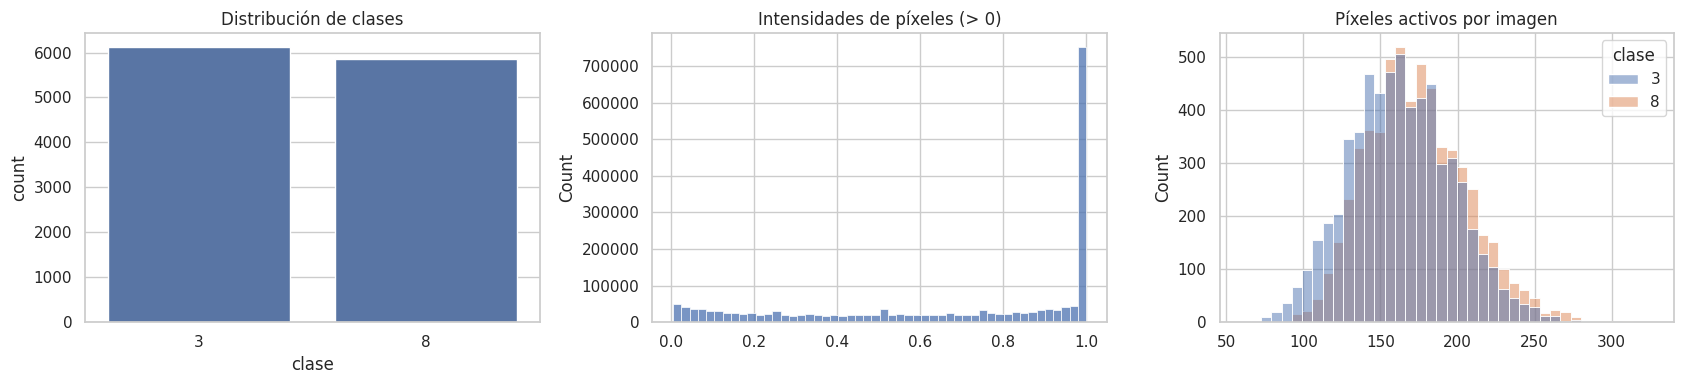

In [ ]:

# Se crea un DataFrame de Pandas para organizar las imágenes procesadas.
# Cada una de las 784 columnas representa un píxel de la imagen,
# identificado mediante un nombre consecutivo (p0, p1, ..., p783).
nombres_pix = [f"p{i}" for i in range(784)]
df = pd.DataFrame(X_train, columns=nombres_pix)

# Se agrega una columna llamada "clase" con la etiqueta de cada imagen:
# 0 para el dígito 3 y 1 para el dígito 8.
df["clase"] = y_train.astype(int)


# Se calcula la proporción de píxeles que tienen intensidad igual a cero
# en todo el conjunto de entrenamiento. Esto permite identificar qué
# tan dispersa es la información de las imágenes.
print(f"Proporción de píxeles en cero: {(X_train == 0).mean():.2%}")

# Se calcula la desviación estándar de cada uno de los 784 píxeles
# considerando todas las imágenes de entrenamiento.
# Los píxeles cuya desviación estándar es cero tienen el mismo valor
# en todas las imágenes, por lo que no aportan variabilidad al conjunto.
print(f"Píxeles constantes (varianza nula) en todo el train: {(X_train.std(0) == 0).sum()}")


# Se crea una figura con tres gráficos organizados horizontalmente
# para visualizar diferentes características del conjunto de datos.
fig, ax = plt.subplots(1, 3, figsize=(17, 4))


# (1) DISTRIBUCIÓN DE CLASES
# Se convierten las etiquetas binarias en los nombres originales
# de los dígitos para facilitar la interpretación del gráfico.
etiquetas = df["clase"].map({
    0: str(CLASE_NEG),
    1: str(CLASE_POS)
})

# Se genera un gráfico de barras que muestra la cantidad de imágenes
# disponibles para cada una de las dos clases.
sns.countplot(x=etiquetas, ax=ax[0])
ax[0].set_title("Distribución de clases")


# (2) DISTRIBUCIÓN DE INTENSIDADES DE LOS PÍXELES
# Se convierten todos los píxeles de las imágenes en un único arreglo
# para analizar la distribución de sus intensidades.
valores = X_train.ravel()

# Se seleccionan únicamente los píxeles con intensidad mayor que cero,
# excluyendo los píxeles negros del análisis.
# Se genera un histograma para observar la frecuencia de las
# diferentes intensidades presentes en las imágenes.
sns.histplot(valores[valores > 0], bins=50, ax=ax[1])
ax[1].set_title("Intensidades de píxeles (> 0)")


# (3) CANTIDAD DE PÍXELES ACTIVOS POR IMAGEN
# Se cuentan los píxeles cuya intensidad es mayor que cero en cada imagen.
# Se utiliza axis=1 para realizar el conteo individualmente por imagen.
# El parámetro hue permite diferenciar las distribuciones de los dígitos 3 y 8.
sns.histplot(
    x=(X_train > 0).sum(axis=1),
    hue=etiquetas,
    bins=40,
    ax=ax[2]
)
ax[2].set_title("Píxeles activos por imagen")


# Se ajusta la distribución de los gráficos para evitar superposiciones
# y se muestran los tres resultados en una misma figura.
plt.tight_layout()
plt.show()


Se realizó un análisis exploratorio del conjunto de datos de entrenamiento con el propósito de identificar las características y la distribución de los píxeles de las imágenes MNIST. Para ello, se organizaron los datos en un DataFrame y se generaron tres gráficos que permitieron analizar la distribución de las clases, las intensidades de los píxeles y la cantidad de píxeles activos por imagen.

Los resultados mostraron que el 78,54 % de los píxeles tiene una intensidad igual a cero, lo que indica que gran parte de las imágenes está compuesta por zonas sin información visual( zonas negras de las imágenes). Asimismo se identificaron 161 posiciones de píxel con varianza nula, es decir, que mantienen el mismo valor en todas las imágenes de entrenamiento, por lo que no presentan variabilidad y no aportan información para diferenciar las clases..

Por otra parte, se comprobó que las clases 3 y 8 tienen una distribución relativamente equilibrada. El análisis de las intensidades permitió observar una concentración importante de valores cercanos a 1, correspondientes a pixeles conalta intensidad, mientras que la comparación de píxeles activos mostró que ambas clases presentan distribuciones similares, aunque existen diferencias en sus frecuencias. Esto demuestra que la cantidad de píxeles activos por sí sola no permite distinguir completamente ambas categorías, por lo que es necesario considerar también la posición y distribución de los píxeles.

Consideración para la siguiente etapa: estos resultados permiten conocer la estructura de los datos antes de entrenar el modelo. La presencia de píxeles constantes podría aprovecharse posteriormente para optimizar el procesamiento, ya que no aportan variabilidad entre las imágenes. Sin embargo, en esta etapa únicamente se identificaron y analizaron, no se eliminaron.

###Visualización de patrones promedio y ejemplos de las clases

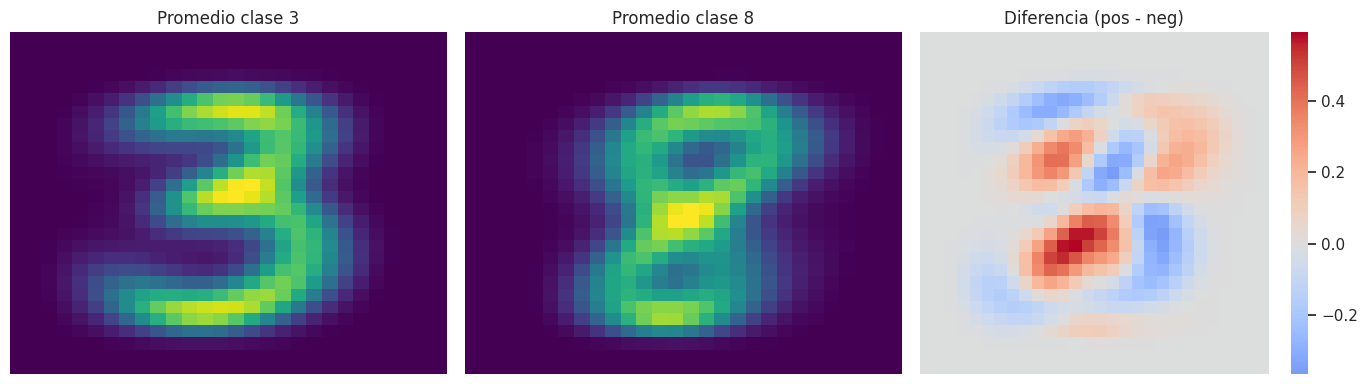

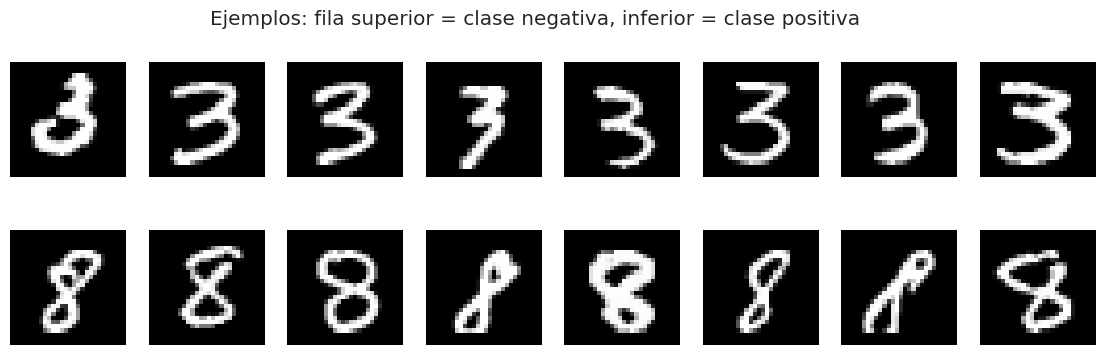

In [ ]:

# Se calcula la imagen promedio de cada clase utilizando todas las imágenes
# de entrenamiento correspondientes a los dígitos 3 y 8.
# Para ello, se promedia la intensidad de cada posición de píxel
# y posteriormente se reconstruye la matriz de 28x28 píxeles.

media_neg = X_train[y_train == 0].mean(axis=0).reshape(28, 28)
media_pos = X_train[y_train == 1].mean(axis=0).reshape(28, 28)

# Se crea una figura con tres gráficos para visualizar las imágenes
# promedio de ambas clases y las diferencias entre sus intensidades.
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

# (1) IMAGEN PROMEDIO DE LA CLASE NEGATIVA
# Se representa el promedio de las intensidades de los píxeles
# de todas las imágenes correspondientes al dígito 3.
sns.heatmap(
    media_neg, cmap="viridis", cbar=False, ax=ax[0],
    xticklabels=False, yticklabels=False
)
ax[0].set_title(f"Promedio clase {CLASE_NEG}")

# (2) IMAGEN PROMEDIO DE LA CLASE POSITIVA
# Se representa el promedio de las intensidades de los píxeles
# de todas las imágenes correspondientes al dígito 8.
sns.heatmap(
    media_pos, cmap="viridis", cbar=False, ax=ax[1],
    xticklabels=False, yticklabels=False
)
ax[1].set_title(f"Promedio clase {CLASE_POS}")

# (3) DIFERENCIA ENTRE LAS IMÁGENES PROMEDIO
# Se resta la imagen promedio de la clase negativa a la positiva
# para identificar las posiciones de píxel donde existen
# mayores diferencias de intensidad entre ambos dígitos.
# Los valores positivos indican mayor intensidad promedio en el 8,
# mientras que los negativos indican mayor intensidad promedio en el 3.
sns.heatmap(
    media_pos - media_neg, cmap="coolwarm", center=0, ax=ax[2],
    xticklabels=False, yticklabels=False
)
ax[2].set_title("Diferencia (pos - neg)")

# Se ajustan los espacios entre los gráficos y se muestra la figura.
plt.tight_layout()
plt.show()


# Se crea una segunda figura para visualizar ejemplos individuales
# de ambas clases y observar las variaciones en la escritura de los dígitos.
fig, ax = plt.subplots(2, 8, figsize=(14, 4))

# Se recorren las dos clases: 0 (dígito 3) y 1 (dígito 8).
for fila, clase in enumerate([0, 1]):

    # Se seleccionan aleatoriamente 8 imágenes de la clase correspondiente,
    # sin repetir imágenes dentro de la selección.
    idx = np.random.choice(
        np.where(y_train == clase)[0], 8, replace=False
    )

    # Se muestran las imágenes seleccionadas en su posición correspondiente.
    for col, i in enumerate(idx):
        ax[fila, col].imshow(
            X_train[i].reshape(28, 28), cmap="gray"
        )

        # Se ocultan los ejes para facilitar la visualización de los dígitos.
        ax[fila, col].axis("off")

# Se agrega un título para identificar las clases representadas en cada fila.
plt.suptitle(
    "Ejemplos: fila superior = clase negativa, inferior = clase positiva"
)
plt.show()


En esta etapa se analizaron visualmente los patrones de las dos clases mediante el cálculo de sus imágenes promedio, la comparación de las intensidades de sus píxeles y la visualización de ejemplos individuales.

En las imágenes promedio se identificó que el dígito 3 concentra sus trazos principalmente en las zonas superior, central e inferior, mientras que el dígito 8 presenta dos áreas interiores delimitadas por sus trazos, una en la parte superior y otra en la inferior, que permiten reconocer su forma característica. Por su parte, el mapa de diferencias permitió identificar las posiciones donde cada clase presenta mayor intensidad promedio: las zonas rojizas corresponden a una mayor intensidad en el dígito 8, las azuladas a una mayor intensidad en el dígito 3 y las grisáceas indican intensidades promedio similares entre ambas categorías. Esto evidencia que los dos dígitos presentan patrones espaciales diferentes.

Adicionalmente, se visualizaron 16 imágenes seleccionadas aleatoriamente, ocho por cada clase. A través de estos ejemplos se observaron variaciones en la forma de escritura, inclinación, tamaño y grosor de los trazos, incluso entre imágenes pertenecientes a una misma categoría. También se identificaron algunas imágenes cuya apariencia visual puede resultar ambigua, aunque conservan su etiqueta original.

En conjunto, este análisis permitió comprender mejor las características visuales del conjunto de datos y evidenciar que la clasificación no depende únicamente de la intensidad o cantidad de píxeles, sino también de su distribución espacial. Por lo tanto, el modelo de regresión logística deberá aprender a reconocer los patrones que permiten diferenciar ambas categorías, considerando las variaciones presentes en las imágenes.

###Análisis de varianza, correlación y localidad espacial de los píxeles

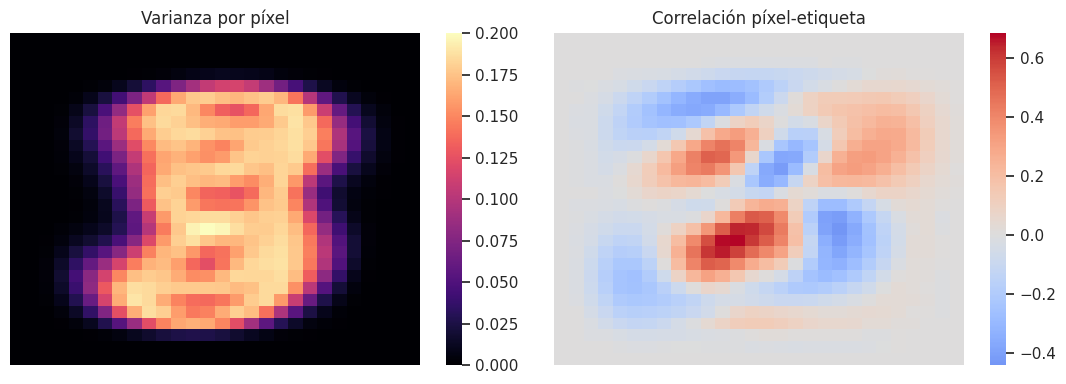

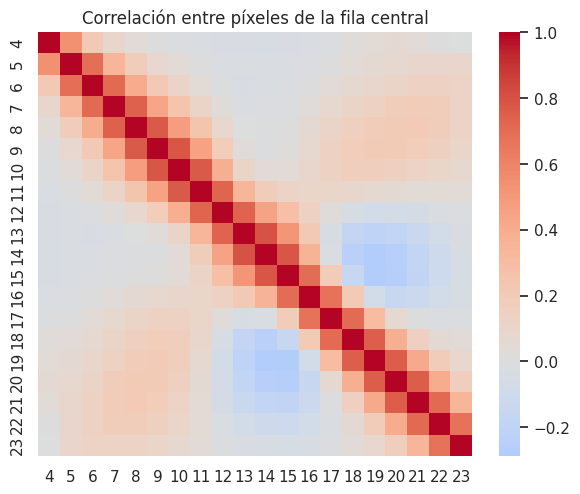

Correlación media entre píxeles vecinos: 0.727
Correlación media entre píxeles distantes (>=10): 0.084


In [ ]:

# Se calcula la varianza de cada una de las 784 posiciones de píxel
# considerando todas las imágenes del conjunto de entrenamiento.
# Posteriormente, los resultados se reorganizan en una matriz de 28x28
# para visualizar en qué zonas existe mayor variabilidad de intensidad.
varianza = X_train.var(axis=0).reshape(28, 28)


# Se calcula la correlación de Pearson entre la intensidad de cada píxel
# y la etiqueta de clasificación de las imágenes.
# Los píxeles constantes se asignan con correlación 0, ya que no es posible
# calcular una correlación cuando su desviación estándar es cero.
corr_etiqueta = np.array([
    np.corrcoef(X_train[:, j], y_train)[0, 1]
    if X_train[:, j].std() > 0 else 0.0
    for j in range(784)
]).reshape(28, 28)


# Se crea una figura con dos gráficos para representar la varianza
# de los píxeles y su correlación con las etiquetas de clasificación.
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# (1) VARIANZA POR PÍXEL
# Se genera un mapa de calor para visualizar la variabilidad
# de la intensidad de cada posición de píxel entre las imágenes.
sns.heatmap(
    varianza, cmap="magma", ax=ax[0],
    xticklabels=False, yticklabels=False
)
ax[0].set_title("Varianza por píxel")

# (2) CORRELACIÓN ENTRE PÍXEL Y ETIQUETA
# Se representa la correlación de cada píxel con la clase de la imagen.
# Los valores positivos indican asociación con la clase 8,
# mientras que los negativos indican asociación con la clase 3.
# Los valores cercanos a cero indican una relación lineal débil.
sns.heatmap(
    corr_etiqueta, cmap="coolwarm", center=0, ax=ax[1],
    xticklabels=False, yticklabels=False
)
ax[1].set_title("Correlación píxel-etiqueta")

# Se ajustan los espacios entre los gráficos y se muestra la figura.
plt.tight_layout()
plt.show()


# Se analiza la correlación entre los píxeles de una fila específica
# de las imágenes: la fila central (fila 14), considerando las columnas 4 a 23.
fila, columnas = 14, list(range(4, 24))

# Se generan los nombres de las columnas del DataFrame correspondientes
# a las posiciones de píxel seleccionadas.
cols_df = [f"p{fila*28 + c}" for c in columnas]

# Se calcula la matriz de correlación de Pearson entre las 20 posiciones
# de píxel seleccionadas, considerando todas las imágenes de entrenamiento.
C = df[cols_df].corr()


# Se genera un mapa de calor para visualizar la relación entre
# las intensidades de los diferentes píxeles de la fila seleccionada.
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    C, cmap="coolwarm", center=0,
    xticklabels=columnas, yticklabels=columnas
)
plt.title("Correlación entre píxeles de la fila central")
plt.show()


# Se calcula la correlación media entre píxeles vecinos y entre
# píxeles distantes para analizar la localidad espacial de los datos.
Cv = C.values

# Se calcula el promedio de correlación entre posiciones consecutivas
# de la fila central, es decir, entre píxeles vecinos horizontalmente.
vecinos = np.mean([
    Cv[i, i + 1] for i in range(len(Cv) - 1)
])

# Se calcula el promedio de correlación entre pares de píxeles
# cuya separación dentro de la fila es de al menos 10 posiciones.
lejanos = np.mean([
    Cv[i, j]
    for i in range(len(Cv))
    for j in range(len(Cv))
    if abs(i - j) >= 10
])

# Se muestran los valores obtenidos para comparar la relación
# entre píxeles cercanos y píxeles distantes.
print(f"Correlación media entre píxeles vecinos: {vecinos:.3f}")
print(f"Correlación media entre píxeles distantes (>=10): {lejanos:.3f}")


En esta etapa se analizaron las características estadísticas de los píxeles mediante el cálculo de su varianza y correlación, con el propósito de identificar patrones que puedan aportar información al proceso de clasificación.

El mapa de varianza permitió identificar cómo cambia la intensidad de cada píxel entre las imágenes del conjunto de entrenamiento. Se observa que la región central, donde se ubican los trazos de los dígitos, presenta mayor varianza (tonos claros según la barra de color), mientras que los bordes de la imagen presentan valores cercanos a cero, ya que sus intensidades se mantienen casi siempre en el fondo. Esto indica que no todas las posiciones aportan la misma información: los píxeles periféricos presentan poca variación entre imágenes y, por tanto, tienen menor capacidad para diferenciar las clases, mientras que los píxeles centrales varían según el dígito y su forma de escritura, por lo que pueden contribuir más a la clasificación.

Por otra parte, el mapa de correlación píxel-etiqueta permitió analizar la relación entre la intensidad de cada píxel y la clase a la que pertenece la imagen. En el gráfico se observan zonas rojizas, que representan píxeles cuya mayor intensidad está asociada con el dígito 8, y zonas azuladas, donde una mayor intensidad está asociada con el dígito 3. Por su parte, las zonas cercanas al gris indican que la intensidad de esos píxeles tiene poca relación con la clase. Esto permite identificar que algunas posiciones presentan diferencias de intensidad entre los dos dígitos y pueden ayudar al modelo a reconocerlos y diferenciarlos durante la clasificación.

Adicionalmente, se estudió la relación entre 20 píxeles consecutivos de la fila central de las imágenes, con el propósito de identificar si las posiciones cercanas presentan comportamientos similares en sus intensidades. Para ello, se calculó la correlación entre los píxeles seleccionados y se comparó el promedio obtenido entre posiciones vecinas con el de posiciones más distantes.

Los resultados mostraron una correlación media de 0.727 entre píxeles vecinos, lo que indica una relación positiva relativamente alta. Esto significa que cuando un píxel presenta una intensidad elevada, los píxeles contiguos también tienden a presentar intensidades elevadas. En contraste, la correlación media entre píxeles separados por al menos 10 posiciones fue de 0.084, un valor cercano a cero que indica una relación lineal muy débil.

Esta diferencia evidencia que existe una relación espacial entre los píxeles, ya que las posiciones cercanas tienden a presentar patrones de intensidad similares porque pueden formar parte de los mismos trazos de los dígitos. Esto demuestra que la posición de los píxeles y su relación con los elementos cercanos son características importantes de las imágenes. Aunque este análisis se limitó a una fila de las imágenes, permite comprender cómo se relacionan los píxeles según su ubicación.

###Implementación y evaluación del modelo baseline con Scikit-Learn.

Tiempo de entrenamiento : 2.508 s
Accuracy : 0.9672
Precision: 0.9681
Recall   : 0.9651
F1-Score : 0.9666


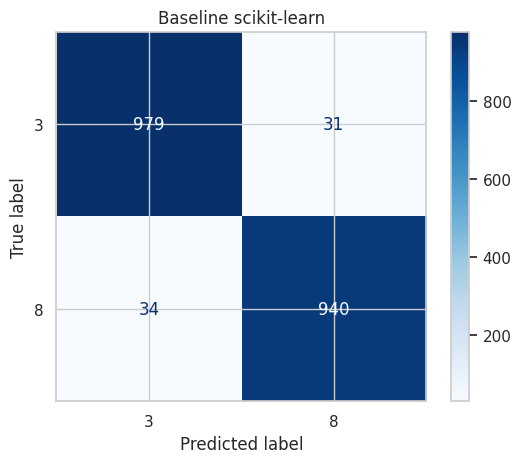

In [ ]:

# Se obtiene la cantidad de imágenes del conjunto de entrenamiento.
# Este valor se utiliza para calcular el parámetro de regularización C
# de Scikit-Learn a partir del LAMBDA definido para la implementación propia.
#
# Scikit-Learn minimiza: C * suma(pérdidas) + 0.5 * ||w||²
# La implementación propia minimiza: promedio(pérdidas) + (LAMBDA / 2) * ||w||²
# Ambas expresiones son equivalentes cuando C = 1 / (LAMBDA * m).
m = X_train.shape[0]
C_SK = 1.0 / (LAMBDA * m)

# Se crea el modelo de Regresión Logística utilizando Scikit-Learn.
# Se establece el parámetro de regularización calculado, se selecciona
# el optimizador LBFGS y se define un máximo de 1000 iteraciones
# para encontrar los parámetros del modelo.
modelo_sk = LogisticRegression(C=C_SK, solver="lbfgs", max_iter=1000)

# Se registra el tiempo inicial y se entrena el modelo con las imágenes
# y etiquetas del conjunto de entrenamiento.
# Posteriormente, se calcula el tiempo total que tomó el entrenamiento.
t0 = time.perf_counter()
modelo_sk.fit(X_train, y_train)
t_fit = time.perf_counter() - t0

# Se utiliza el modelo entrenado para predecir las clases
# de las imágenes del conjunto de prueba.
y_pred = modelo_sk.predict(X_test)

# Se muestra el tiempo de entrenamiento y se calculan las métricas
# de evaluación comparando las etiquetas reales con las predicciones:
# Accuracy: proporción total de clasificaciones correctas.
# Precision: proporción de predicciones del dígito 8 que fueron correctas.
# Recall: proporción de imágenes del dígito 8 identificadas correctamente.
# F1-Score: medida que combina Precision y Recall.
print(f"Tiempo de entrenamiento : {t_fit:.3f} s")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred):.4f}")

# Se genera la matriz de confusión para visualizar la cantidad de
# imágenes clasificadas correctamente y los errores cometidos.
# Las filas representan las clases reales y las columnas las predicciones.
# Se utilizan las etiquetas originales de los dígitos 3 y 8.
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=[CLASE_NEG, CLASE_POS]
).plot(cmap="Blues")

plt.title("Baseline scikit-learn")
plt.show()


En esta etapa se implementó un modelo de Regresión Logística utilizando la biblioteca Scikit-Learn, con el propósito de establecer una línea base (baseline) para comparar posteriormente su rendimiento con la implementación desarrollada en C++.

Para mantener una configuración comparable, se calculó el parámetro de regularización C a partir del valor de LAMBDA definido anteriormente. Posteriormente, se entrenó el modelo utilizando el optimizador LBFGS y se evaluó su desempeño sobre el conjunto de prueba.

Los resultados muestran que el modelo obtuvo un *Accuracy* de 96.72 %, *Precision* de 96.81 %, *Recall* de 96.51 % y *F1-Score* de 96.66 %, con un tiempo de entrenamiento de 4.084 segundos. Estas métricas se calcularon comparando las etiquetas reales con las predicciones del modelo. El Accuracy representa el porcentaje total de imágenes clasificadas correctamente, mientras que Precision, Recall y F1-Score evalúan específicamente el desempeño en la identificación del dígito 8, que fue definido como la clase positiva.

Por su parte, la matriz de confusión permite visualizar con mayor detalle estos resultados. En ella se observa que el modelo clasificó correctamente 979 imágenes del dígito 3 y 940 del dígito 8, para un total de 1919 aciertos de las 1984 imágenes evaluadas. Los 65 errores de clasificación se distribuyeron de la siguiente manera:

1. 31 imágenes del dígito 3 fueron clasificadas incorrectamente como 8.
2. 34 imágenes del dígito 8 fueron clasificadas incorrectamente como 3.

En general, los resultados muestran que el modelo logró un buen desempeño en la clasificación de ambas clases, con una exactitud del 96.72 % y una cantidad reducida de errores.

##FASE B: Implementación de bajo nivel en C++

###Exportación de los conjuntos de datos a formato binario para C++.

In [ ]:

# Función encargada de exportar las características (X) y etiquetas (y)
# de un conjunto de datos a un archivo binario para su lectura en C++.
def exportar_binario(X, y, ruta):
    """
    Formato del archivo:
      [int32 m][int32 n][m*n float32 de X en orden fila-mayor][m float32 de y]

    Se utiliza formato binario para que C++ pueda leer directamente
    los datos en memoria, evitando tener que interpretar archivos de texto.
    """

    # Se obtiene la cantidad de imágenes (m) y la cantidad de píxeles (n).
    m, n = X.shape

    # Se abre el archivo en modo escritura binaria ("wb").
    with open(ruta, "wb") as f:

        # Se guardan las dimensiones de la matriz:
        # m = número de imágenes y n = número de características por imagen.
        # Se utilizan enteros de 32 bits (int32).
        f.write(np.array([m, n], dtype=np.int32).tobytes())

        # Se guardan los valores de los píxeles como números float32.
        # ascontiguousarray garantiza que los datos estén organizados
        # de forma consecutiva por filas en memoria.
        f.write(np.ascontiguousarray(X, dtype=np.float32).tobytes())

        # Se guardan las etiquetas de clasificación como valores float32.
        f.write(y.astype(np.float32).tobytes())


# Se definen los nombres de los archivos binarios para entrenamiento y prueba.
TRAIN_BIN, TEST_BIN = "datos_train.bin", "datos_test.bin"

# Se exportan los respectivos conjuntos de datos a sus archivos binarios.
exportar_binario(X_train, y_train, TRAIN_BIN)
exportar_binario(X_test, y_test, TEST_BIN)

# Se muestra el tamaño de cada archivo en megabytes.
print({f: f"{os.path.getsize(f)/1e6:.1f} MB" for f in (TRAIN_BIN, TEST_BIN)})


{'datos_train.bin': '37.6 MB', 'datos_test.bin': '6.2 MB'}


Se prepararon los conjuntos de entrenamiento y prueba para su uso en la implementación en C++. Para ello, se desarrolló una función que exporta los datos en formato binario, almacenando las dimensiones de cada conjunto, los valores de los píxeles y las etiquetas correspondientes a cada imagen.

Como resultado, se generaron los archivos *datos_train.bin* y *datos_test.bin*. Este formato permite utilizar los mismos conjuntos de datos en Python y C++, facilitando una comparación equitativa entre ambas implementaciones.

###Configuración del entorno C++ y carga de los conjuntos de datos

In [ ]:

%%writefile main.cpp

// =============================================================================
// main.cpp - Regresión Logística binaria con Eigen (C++17)
//
// El programa se organiza en diferentes etapas:
// 1. Preprocesamiento y preparación del código.
// 2. Compilación y generación del ejecutable.
// 3. Enlazado de las bibliotecas necesarias.
// 4. Ejecución del programa, carga de datos, entrenamiento y evaluación.
//
// También se utilizan diferentes clases de almacenamiento:
// - static: limita la visibilidad de variables y funciones a este archivo.
// - constexpr: define valores constantes conocidos en compilación.
// - const: indica que un valor no será modificado.
// =============================================================================

// Se incluyen las bibliotecas necesarias para el funcionamiento del programa.
#include <Eigen/Dense>  // Operaciones matemáticas con matrices y vectores.
#include <algorithm>    // Funciones como fill().
#include <chrono>       // Medición de tiempos de ejecución.
#include <cmath>        // Funciones matemáticas como exp().
#include <cstdint>      // Tipos de datos enteros de tamaño específico.
#include <cstdlib>      // Funciones generales, como exit().
#include <fstream>      // Lectura de archivos.
#include <iomanip>      // Formato de los valores mostrados en pantalla.
#include <iostream>     // Entrada y salida de información.
#include <string>       // Manejo de cadenas de texto.
#include <vector>       // Almacenamiento dinámico de datos.

// ----------------------------- TIPOS DE DATOS --------------------------------

// Se define float como tipo de dato principal para los cálculos.
// Se utiliza precisión de 32 bits, igual que en los archivos binarios
// generados previamente desde Python.
using Scalar = float;

// Se selecciona el orden de almacenamiento de las matrices.
// Por defecto se utiliza RowMajor (fila-mayor).
// Si se compila con -DLAYOUT_COLMAJOR, se utiliza ColMajor (columna-mayor).
// Esto permite comparar cómo el orden de almacenamiento influye
// en el acceso a los datos y en el rendimiento de caché.
#ifdef LAYOUT_COLMAJOR
constexpr int kLayout = Eigen::ColMajor;
#else
constexpr int kLayout = Eigen::RowMajor;
#endif

// Se definen los tipos de matrices y vectores que se utilizarán.
// Matrix: matriz dinámica cuyo orden depende de kLayout.
// RowMat: matriz dinámica almacenada siempre por filas.
// Vec: vector dinámico de una sola columna.
using Matrix = Eigen::Matrix<Scalar, Eigen::Dynamic, Eigen::Dynamic, kLayout>;
using RowMat = Eigen::Matrix<Scalar, Eigen::Dynamic, Eigen::Dynamic, Eigen::RowMajor>;
using Vec    = Eigen::Matrix<Scalar, Eigen::Dynamic, 1>;

// Se define un reloj para medir los tiempos de ejecución.
using Reloj = std::chrono::steady_clock;

// Se declara un contador global que acumula los bytes leídos desde los archivos.
// Al ser static, solo puede utilizarse dentro de este archivo.
static std::size_t g_bytesLeidos = 0;

// Función auxiliar que calcula el tiempo transcurrido en segundos
// entre dos instantes registrados por el reloj.
static double segundos(Reloj::time_point a, Reloj::time_point b) {
    return std::chrono::duration<double>(b - a).count();
}

// Función que consulta el archivo /proc/self/status de Linux
// para obtener el valor máximo de memoria residente utilizado
// por el proceso durante su ejecución (VmHWM).
// El resultado se expresa en megabytes.
static double picoMemoriaMB() {
    std::ifstream f("/proc/self/status");
    std::string linea;

    // Se recorren las líneas del archivo hasta encontrar VmHWM.
    while (std::getline(f, linea)) {
        if (linea.rfind("VmHWM:", 0) == 0)
            return std::stol(linea.substr(6)) / 1024.0;
    }

    // Si no se encuentra el dato, se devuelve -1.
    return -1.0;
}

// ------------------------------- DATASET -------------------------------------

// Estructura que agrupa las características y etiquetas del conjunto de datos.
struct Dataset {
    Matrix X;  // Matriz con las imágenes: filas = imágenes, columnas = píxeles.
    Vec    y;  // Vector con las etiquetas de cada imagen (0 o 1).
};

// Función encargada de leer un archivo binario generado desde Python.
static Dataset cargarDataset(const std::string& ruta) {

    // Se abre el archivo en modo lectura binaria.
    std::ifstream f(ruta, std::ios::binary);

    // Si el archivo no puede abrirse, se muestra un error y termina el programa.
    if (!f) {
        std::cerr << "No se pudo abrir " << ruta << "\n";
        std::exit(1);
    }

    // Se leen las dos dimensiones almacenadas al inicio del archivo:
    // m = cantidad de imágenes y n = cantidad de características por imagen.
    std::int32_t cab[2];
    f.read(reinterpret_cast<char*>(cab), sizeof(cab));

    const Eigen::Index m = cab[0], n = cab[1];

    // Se reserva un espacio de memoria contiguo para almacenar los píxeles.
    // El vector tendrá m*n elementos de tipo float.
    std::vector<Scalar> buffer(static_cast<std::size_t>(m * n));

    // Se obtiene un puntero al primer elemento del espacio reservado.
    Scalar* ptr = buffer.data();

    // Se leen directamente los valores del archivo binario en el buffer.
    // De esta manera se evita leer y convertir los datos uno por uno.
    f.read(reinterpret_cast<char*>(ptr),
           static_cast<std::streamsize>(m * n * sizeof(Scalar)));

    // Se actualiza el contador de bytes leídos correspondientes a los píxeles.
    g_bytesLeidos += static_cast<std::size_t>(m * n * sizeof(Scalar));

    // Se crea una estructura para almacenar los datos cargados.
    Dataset d;

    // Eigen::Map permite interpretar el buffer existente como una matriz,
    // sin crear una copia adicional en este paso.
    // Se indica RowMat porque los datos fueron exportados desde Python
    // en orden fila-mayor.
    //
    // Al asignar el resultado a d.X, los datos se copian a la matriz
    // utilizando el orden de almacenamiento definido para Matrix.
    d.X = Eigen::Map<const RowMat>(ptr, m, n);

    // Se reserva espacio para almacenar las m etiquetas.
    d.y.resize(m);

    // Se leen las etiquetas desde el archivo binario.
    f.read(reinterpret_cast<char*>(d.y.data()),
           static_cast<std::streamsize>(m * sizeof(Scalar)));

    // Se actualiza el contador de bytes leídos correspondientes a las etiquetas.
    g_bytesLeidos += static_cast<std::size_t>(m * sizeof(Scalar));

    // Se devuelve el conjunto de datos completo.
    // El buffer temporal se libera automáticamente al salir de la función.
    return d;
}

// ------------------------------- SIGMOIDE ------------------------------------

// Función sigmoide: transforma los valores de entrada en probabilidades
// comprendidas entre 0 y 1.
// Se aplica elemento a elemento sobre el vector recibido.
static inline Vec sigmoide(const Vec& z) {
    return (Scalar(1) + (-z.array()).exp()).inverse().matrix();
}

// --------------------------- REGRESIÓN LOGÍSTICA -----------------------------

// Clase que implementa el modelo de regresión logística binaria.
class RegresionLogistica {
public:

    // Constructor: recibe la tasa de aprendizaje, el número de épocas
    // y el parámetro de regularización.
    RegresionLogistica(Scalar lr, int epocas, Scalar lambda)
        : lr_(lr), epocas_(epocas), lambda_(lambda), b_(0) {}

    // Entrenamiento mediante gradiente descendente de lote completo.
    // X e y se reciben por referencia constante para evitar copiar los datos.
    void ajustar(const Matrix& X, const Vec& y) {

        const Eigen::Index m = X.rows(), n = X.cols();

        // Se inicializan los pesos y el sesgo en cero.
        w_ = Vec::Zero(n);
        b_ = 0;

        // Se crean los vectores de trabajo una sola vez fuera del ciclo.
        // Así se reutilizan durante las diferentes épocas de entrenamiento.
        Vec z(m), p(m), err(m), gw(n);

        // Ciclo principal de entrenamiento.
        for (int e = 0; e < epocas_; ++e) {

            // Se calcula la combinación lineal de las características y los pesos.
            z.noalias() = X * w_;

            // Se agrega el término de sesgo.
            z.array() += b_;

            // Se aplica la función sigmoide para obtener probabilidades.
            p = sigmoide(z);

            // Se calcula el error entre las probabilidades y las etiquetas reales.
            err = p - y;

            // Se calcula el gradiente correspondiente a los pesos.
            gw.noalias() = X.transpose() * err;

            // Se promedia el gradiente y se agrega la regularización L2.
            gw = gw / Scalar(m) + lambda_ * w_;

            // Se actualiza el sesgo utilizando el promedio del error.
            b_ -= lr_ * err.mean();

            // Se actualizan los pesos con la tasa de aprendizaje.
            w_ -= lr_ * gw;

            // Se muestra la pérdida cada 200 épocas y al finalizar.
            if (e % 200 == 0 || e == epocas_ - 1)
                std::cerr << "[epoca " << e << "] perdida = "
                          << perdida(X, y) << "\n";
        }
    }

    // Calcula la probabilidad de pertenecer a la clase positiva
    // para cada imagen del conjunto recibido.
    Vec probabilidades(const Matrix& X) const {
        Vec z = X * w_;
        z.array() += b_;
        return sigmoide(z);
    }

    // Calcula la función de pérdida mediante entropía cruzada binaria
    // y agrega el término de regularización L2.
    Scalar perdida(const Matrix& X, const Vec& y) const {

        const Vec p = probabilidades(X);

        // Se utiliza un valor pequeño para evitar logaritmos de cero.
        constexpr Scalar eps = 1e-7f;

        const Scalar ce = -(y.array() * (p.array() + eps).log()
                          + (Scalar(1) - y.array())
                          * (Scalar(1) - p.array() + eps).log()).mean();

        return ce + Scalar(0.5) * lambda_ * w_.squaredNorm();
    }

private:

    // Parámetros internos del modelo.
    Scalar lr_;       // Tasa de aprendizaje.
    int epocas_;      // Número de épocas de entrenamiento.
    Scalar lambda_;   // Parámetro de regularización.
    Vec w_;           // Vector de pesos del modelo.
    Scalar b_;        // Sesgo del modelo.
};

// -------------------------------- MÉTRICAS -----------------------------------

// Estructura para almacenar las métricas de clasificación.
struct Metricas {
    double acc;
    double prec;
    double rec;
    double f1;
};

// Función que compara las predicciones con las etiquetas reales
// y calcula Accuracy, Precision, Recall y F1-Score.
static Metricas evaluar(const Vec& p, const Vec& y) {

    // Contadores para los verdaderos positivos, falsos positivos,
    // verdaderos negativos y falsos negativos.
    long tp = 0, fp = 0, tn = 0, fn = 0;

    // Se clasifica cada predicción utilizando un umbral de 0.5.
    for (Eigen::Index i = 0; i < p.size(); ++i) {

        const bool pred = p[i] >= 0.5f;
        const bool real = y[i] >= 0.5f;

        if (pred && real) ++tp;
        else if (pred && !real) ++fp;
        else if (!pred && real) ++fn;
        else ++tn;
    }

    // Se calculan Precision y Recall evitando divisiones por cero.
    const double prec = (tp + fp) ? double(tp) / (tp + fp) : 0.0;
    const double rec  = (tp + fn) ? double(tp) / (tp + fn) : 0.0;

    // Se retornan las cuatro métricas de evaluación.
    return {
        double(tp + tn) / (tp + tn + fp + fn),
        prec,
        rec,
        (prec + rec) ? 2 * prec * rec / (prec + rec) : 0.0
    };
}

// ---------------------- ESTUDIO DE LOCALIDAD (FASE C) ------------------------

// Calcula el gradiente en dos pasadas:
// primero se calcula X*w y después se recorre X para calcular X^T*error.
static void gradienteDosPasadas(
    const RowMat& R, const Vec& y, const Vec& w, Scalar b,
    Vec& gw, Scalar& gb
) {
    Vec z = R * w;
    z.array() += b;

    const Vec err = sigmoide(z) - y;

    gw = R.transpose() * err / Scalar(R.rows());
    gb = err.mean();
}

// Calcula el gradiente fusionando el proceso en una sola pasada.
// Cada fila se utiliza para calcular la combinación lineal y,
// posteriormente, para acumular el gradiente correspondiente.
static void gradienteFusionado(
    const RowMat& R, const Vec& y, const Vec& w, Scalar b,
    Vec& gw, Scalar& gb
) {

    const Eigen::Index m = R.rows(), n = R.cols();

    // Se obtiene un puntero al primer elemento de la matriz.
    const Scalar* base = R.data();

    // Se inicializan los acumuladores del gradiente y del sesgo.
    gw.setZero();
    gb = 0;

    // Se recorren las imágenes una por una.
    for (Eigen::Index i = 0; i < m; ++i) {

        // Se obtiene la dirección de memoria donde comienza la fila actual.
        const Scalar* x = base + i * n;

        Scalar z = b;

        // Se calcula la combinación lineal de la imagen actual.
        for (Eigen::Index j = 0; j < n; ++j)
            z += x[j] * w[j];

        // Se calcula el error de predicción de la imagen.
        const Scalar e =
            Scalar(1) / (Scalar(1) + std::exp(-z)) - y[i];

        // Se acumula el gradiente del sesgo.
        gb += e;

        // Se acumula el gradiente de cada peso.
        for (Eigen::Index j = 0; j < n; ++j)
            gw[j] += e * x[j];
    }

    // Se promedian los gradientes.
    gw /= Scalar(m);
    gb /= Scalar(m);
}

// Función que compara diferentes formas de recorrer y procesar los datos.
static void benchLocalidad(const Matrix& Xl, const Vec& y) {

    // Se crea una copia de la matriz en orden fila-mayor.
    const RowMat R = Xl;

    const Eigen::Index m = R.rows(), n = R.cols();

    // Se obtiene un puntero al inicio de los datos.
    const Scalar* a = R.data();

    // Se crea un vector de pesos de prueba.
    const Vec w = Vec::Constant(n, Scalar(0.01));

    // Vector auxiliar para almacenar los resultados.
    std::vector<Scalar> out(m);

    // Se repite cada prueba 100 veces para medir su tiempo promedio.
    constexpr int REPS = 100;

    // Acumulador utilizado para conservar los resultados de los recorridos.
    double chk = 0;

    // (1) Recorrido por filas:
    // los elementos de cada fila se encuentran almacenados consecutivamente.
    auto t0 = Reloj::now();

    for (int r = 0; r < REPS; ++r) {
        for (Eigen::Index i = 0; i < m; ++i) {

            const Scalar* fila = a + i * n;
            Scalar s = 0;

            for (Eigen::Index j = 0; j < n; ++j)
                s += fila[j] * w[j];

            out[i] = s;
        }

        chk += out[0];
    }

    auto t1 = Reloj::now();

    // (2) Recorrido por columnas:
    // se accede a posiciones separadas dentro de las diferentes filas.
    for (int r = 0; r < REPS; ++r) {

        std::fill(out.begin(), out.end(), Scalar(0));

        for (Eigen::Index j = 0; j < n; ++j) {

            const Scalar wj = w[j];

            for (Eigen::Index i = 0; i < m; ++i)
                out[i] += a[i * n + j] * wj;
        }

        chk += out[0];
    }

    auto t2 = Reloj::now();

    // (3) Se mide el tiempo del cálculo del gradiente en dos pasadas.
    // (4) Se mide el tiempo del cálculo del gradiente fusionado en una pasada.
    Vec g1(n), g2(n);
    Scalar b1 = 0, b2 = 0;

    auto t3 = Reloj::now();

    for (int r = 0; r < REPS; ++r)
        gradienteDosPasadas(R, y, w, 0.f, g1, b1);

    auto t4 = Reloj::now();

    for (int r = 0; r < REPS; ++r)
        gradienteFusionado(R, y, w, 0.f, g2, b2);

    auto t5 = Reloj::now();

    // Se muestran los tiempos promedio de cada prueba en milisegundos.
    // También se calcula la diferencia máxima entre los gradientes
    // obtenidos por los dos métodos.
    std::cout << std::fixed << std::setprecision(6)
              << "loc_filas_ms="      << 1e3 * segundos(t0, t1) / REPS << "\n"
              << "loc_columnas_ms="   << 1e3 * segundos(t1, t2) / REPS << "\n"
              << "loc_dospasadas_ms=" << 1e3 * segundos(t3, t4) / REPS << "\n"
              << "loc_fusionado_ms="  << 1e3 * segundos(t4, t5) / REPS << "\n"
              << "loc_diff_max="      << (g1 - g2).cwiseAbs().maxCoeff() << "\n"
              << "checksum="          << chk << "\n";
}

// ---------------------------------- MAIN -------------------------------------

// El programa admite dos modos de ejecución:
//
// train: entrena el modelo y evalúa sus resultados.
// locality: ejecuta las pruebas de recorrido y localidad.
//
// Ejemplos:
// ./prog train datos_train.bin datos_test.bin [lr] [epocas] [lambda]
// ./prog locality datos_train.bin

int main(int argc, char** argv) {

    // Se comprueba que se hayan proporcionado los argumentos necesarios.
    if (argc < 3) {
        std::cerr << "Uso: prog train|locality archivos...\n";
        return 1;
    }

    // Se obtiene el modo de ejecución indicado.
    const std::string modo = argv[1];

    // Modo de ejecución para estudiar la localidad.
    if (modo == "locality") {

        const Dataset tr = cargarDataset(argv[2]);

        benchLocalidad(tr.X, tr.y);

        return 0;
    }

    // Modo de ejecución para entrenar y evaluar el modelo.
    if (modo == "train" && argc >= 4) {

        // Se reciben los parámetros del modelo.
        // Si no se proporcionan, se utilizan los valores predeterminados.
        const Scalar lr = argc > 4 ? std::stof(argv[4]) : 0.1f;
        const int epocas = argc > 5 ? std::stoi(argv[5]) : 1000;
        const Scalar lambda = argc > 6 ? std::stof(argv[6]) : 1e-4f;

        // Se cargan los conjuntos de entrenamiento y prueba.
        const Dataset tr = cargarDataset(argv[2]);
        const Dataset te = cargarDataset(argv[3]);

        // Se crea el modelo de regresión logística.
        RegresionLogistica modelo(lr, epocas, lambda);

        // Se mide el tiempo de entrenamiento.
        const auto t0 = Reloj::now();

        modelo.ajustar(tr.X, tr.y);

        const auto t1 = Reloj::now();

        // Se calculan las probabilidades sobre el conjunto de prueba.
        const Vec p = modelo.probabilidades(te.X);

        const auto t2 = Reloj::now();

        // Se calculan las métricas de clasificación.
        const Metricas mt = evaluar(p, te.y);

        // Se muestran los resultados en formato clave=valor
        // para que puedan ser leídos posteriormente desde Python.
        std::cout << std::fixed << std::setprecision(6)
                  << "tiempo_entrenamiento_s=" << segundos(t0, t1) << "\n"
                  << "tiempo_prediccion_s=" << segundos(t1, t2) << "\n"
                  << "memoria_pico_mb=" << picoMemoriaMB() << "\n"
                  << "accuracy=" << mt.acc << "\n"
                  << "precision=" << mt.prec << "\n"
                  << "recall=" << mt.rec << "\n"
                  << "f1=" << mt.f1 << "\n";

        return 0;
    }

    // Si se recibe un modo o conjunto de argumentos no válido, se informa el error.
    std::cerr << "Argumentos inválidos.\n";
    return 1;
}


Writing main.cpp


Se desarrolló la implementación de la regresión logística binaria en C++ utilizando la biblioteca Eigen para realizar las operaciones matemáticas con matrices y vectores. Inicialmente, se definieron los tipos de datos, las estructuras y las funciones necesarias para cargar los conjuntos de entrenamiento y prueba generados previamente en Python.

Posteriormente, se implementaron la función sigmoide, el algoritmo de gradiente descendente y las métricas de evaluación (Accuracy, Precision, Recall y F1-Score). Adicionalmente, se incorporaron funciones para analizar diferentes patrones de acceso a los datos, comparando recorridos por filas y columnas, así como el cálculo del gradiente en dos pasadas y en una sola pasada.

Finalmente, se implementó la función principal (`main()`), encargada de controlar los modos de ejecución del programa, permitiendo realizar el entrenamiento y la evaluación del modelo o ejecutar las pruebas de localidad. Esta implementación servirá como base para generar las diferentes versiones del programa y realizar las comparaciones de rendimiento.

---

Se desarrolló la implementación de la regresión logística binaria en C++ utilizando la biblioteca Eigen para realizar las operaciones con matrices y vectores. El modelo incluye la función sigmoide, el algoritmo de gradiente descendente para ajustar los pesos y las métricas de evaluación (Accuracy, Precision, Recall y F1-Score).

Para hacer eficiente el manejo de memoria, los datos se pasan a las funciones mediante referencias, evitando copiar las matrices de imágenes. Además, se incorporaron funciones para estudiar cómo influye el orden de acceso a los datos en el rendimiento, lo cual se analiza más adelante.

###Compilación del programa y generación de variantes para el benchmark

In [ ]:
%%bash

# Se detiene la ejecución si alguna instrucción presenta un error.
set -e

# Se define la ruta donde se encuentra instalada la biblioteca Eigen.
EIGEN=/usr/include/eigen3


# VERIFICACIÓN DEL ARCHIVO FUENTE

# Se comprueba que main.cpp exista.
if [ ! -f main.cpp ]; then
    echo "ERROR: No se encontró el archivo main.cpp."
    exit 1
fi

# Se comprueba que el archivo contenga la función principal main().
if ! grep -qE 'int[[:space:]]+main[[:space:]]*\(' main.cpp; then
    echo "ERROR: No se encontró la función main() en main.cpp."
    echo "Verifica que el archivo contenga la implementación completa."
    exit 1
fi

echo "Verificación de main.cpp completada correctamente."


# FASES DEL PROCESO DE COMPILACIÓN

# 1. PREPROCESAMIENTO
# Expande las directivas #include y las macros del código fuente.
# El resultado es un archivo con el código preparado para la compilación.
g++ -std=c++17 -E -I$EIGEN main.cpp -o main.ii

# 2. COMPILACIÓN A ENSAMBLADOR
# Traduce el código C++ a instrucciones de lenguaje ensamblador.
# Se utiliza el nivel de optimización O2.
g++ -std=c++17 -O2 -S -I$EIGEN main.cpp -o main.s

# 3. ENSAMBLADO
# Convierte el código ensamblador en un archivo de código objeto.
g++ -std=c++17 -O2 -c -I$EIGEN main.cpp -o main.o

# 4. ENLAZADO
# Integra el archivo objeto con las bibliotecas necesarias
# para generar un ejecutable.
g++ main.o -o lr_enlazado

# Se muestran las líneas generadas durante el preprocesamiento
# y la compilación a lenguaje ensamblador.
echo ""
echo "RESULTADOS DE COMPILACIÓN"
echo "Líneas tras preprocesar: $(wc -l < main.ii)"
echo "Líneas de ensamblador: $(wc -l < main.s)"

# Se consulta el tamaño de las secciones del archivo objeto:
# text: instrucciones del programa.
# data: datos globales o estáticos inicializados.
# bss: datos globales o estáticos no inicializados.
echo ""
echo "TAMAÑO DEL ARCHIVO OBJETO"
size main.o


# GENERACIÓN DE VARIANTES PARA EL BENCHMARK

# A) FILA-MAYOR CON OPTIMIZACIÓN O2
# Se utiliza almacenamiento por filas y optimización O2.
g++ -std=c++17 -O2 -I$EIGEN main.cpp -o lr_row_O2

# B) FILA-MAYOR CON OPTIMIZACIÓN O3
# Se utiliza almacenamiento por filas, optimización O3
# y las instrucciones disponibles en la arquitectura del procesador.
g++ -std=c++17 -O3 -march=native -I$EIGEN main.cpp -o lr_row_O3

# C) COLUMNA-MAYOR CON OPTIMIZACIÓN O3
# Se utiliza almacenamiento por columnas, manteniendo la optimización O3
# y las instrucciones disponibles en la arquitectura del procesador.
g++ -std=c++17 -O3 -march=native -DLAYOUT_COLMAJOR -I$EIGEN main.cpp -o lr_col_O3


# VERIFICACIÓN DE LOS EJECUTABLES

# Se muestran los archivos ejecutables generados y sus tamaños.
echo ""
echo "EJECUTABLES GENERADOS"
ls -lh lr_row_O2 lr_row_O3 lr_col_O3


Verificación de main.cpp completada correctamente.

RESULTADOS DE COMPILACIÓN
Líneas tras preprocesar: 148604
Líneas de ensamblador: 8523

TAMAÑO DEL ARCHIVO OBJETO
   text	   data	    bss	    dec	    hex	filename
  43923	      8	      8	  43939	   aba3	main.o

EJECUTABLES GENERADOS
-rwxr-xr-x 1 root root 78K Nov 12 02:09 lr_col_O3
-rwxr-xr-x 1 root root 68K Nov 12 02:08 lr_row_O2
-rwxr-xr-x 1 root root 82K Nov 12 02:08 lr_row_O3


En esta sección se realizó la compilación del código fuente `main.cpp`, verificando que contara con la implementación completa del programa. Para ello, se llevaron a cabo las etapas de preprocesamiento, traducción a lenguaje ensamblador, ensamblado y enlazado, con el propósito de generar los archivos ejecutables.

Posteriormente, se generaron tres versiones del programa con diferentes configuraciones para el benchmark:

- **lr_row_O2:** almacenamiento por filas con optimización O2.
- **lr_row_O3:** almacenamiento por filas con optimización O3.
- **lr_col_O3:** almacenamiento por columnas con optimización O3.

La compilación finalizó correctamente y se verificó la generación de los tres ejecutables. Estas versiones se utilizarán para comparar cómo influyen los niveles de optimización y la organización de los datos en el rendimiento de la implementación en C++.

##FASE C: Optimización y evaluación

###Implementación del script de entrenamiento y evaluación en Python

In [ ]:

%%writefile train_python.py

# Script independiente para entrenar y evaluar los modelos en Python
# utilizando los mismos conjuntos de datos binarios que la implementación en C++.
# Se ejecuta como un proceso separado para medir el consumo máximo de memoria.

# Se importan las bibliotecas necesarias.
import sys, time, resource
import numpy as np
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Se reciben los argumentos necesarios para ejecutar el programa:
# modo de entrenamiento, rutas de los archivos y parámetros del modelo.
modo, ruta_train, ruta_test = sys.argv[1:4]
lr, epocas, lam = float(sys.argv[4]), int(sys.argv[5]), float(sys.argv[6])

# Función para cargar los archivos binarios generados anteriormente.
# Se recuperan las dimensiones, la matriz de características y las etiquetas.
def cargar(ruta):
    with open(ruta, "rb") as f:
        m, n = np.fromfile(f, dtype=np.int32, count=2)
        X = np.fromfile(f, dtype=np.float32, count=m * n).reshape(m, n)
        y = np.fromfile(f, dtype=np.float32, count=m)
    return X, y

# Se cargan los conjuntos de entrenamiento y prueba.
Xtr, ytr = cargar(ruta_train)
Xte, yte = cargar(ruta_test)
m, n = Xtr.shape

# Se registra el tiempo inicial para medir el entrenamiento.
t0 = time.perf_counter()

# Se selecciona el modelo de acuerdo con el modo de ejecución.
if modo == "sklearn":

    # Se configura Scikit-Learn utilizando el parámetro de regularización
    # equivalente al empleado en la implementación propia.
    modelo = LogisticRegression(C=1.0 / (lam * m), solver="lbfgs", max_iter=1000)

    # Se entrena el modelo y se registra el tiempo de finalización.
    modelo.fit(Xtr, ytr)
    t1 = time.perf_counter()

    # Se calculan las probabilidades de pertenecer a la clase positiva.
    prob = modelo.predict_proba(Xte)[:, 1]

else:

    # Se inicializan los pesos y el sesgo para la implementación propia.
    w = np.zeros(n, dtype=np.float32)
    b = np.float32(0.0)

    # Se ejecuta el gradiente descendente utilizando los mismos
    # parámetros y el mismo procedimiento de actualización que en C++.
    for _ in range(epocas):
        z = Xtr @ w + b
        p = expit(z)
        err = p - ytr
        gw = Xtr.T @ err / m + lam * w
        b -= lr * err.mean()
        w -= lr * gw

    # Se registra el tiempo de finalización del entrenamiento.
    t1 = time.perf_counter()

    # Se calculan las probabilidades sobre el conjunto de prueba.
    prob = expit(Xte @ w + b)

# Se registra el tiempo después de realizar las predicciones.
t2 = time.perf_counter()

# Se convierten las probabilidades en predicciones de clase:
# valores iguales o superiores a 0.5 corresponden a la clase positiva.
pred = (prob >= 0.5).astype(np.float32)

# Se consulta el pico máximo de memoria (VmHWM), igual que en la versión C++.
def pico_memoria_mb():
    with open("/proc/self/status") as f:
        for l in f:
            if l.startswith("VmHWM:"):
                return int(l.split()[1]) / 1024.0

pico_mb = pico_memoria_mb()

# Se muestran los tiempos de entrenamiento y predicción,
# el consumo máximo de memoria y las métricas de evaluación.
print(f"tiempo_entrenamiento_s={t1 - t0:.6f}")
print(f"tiempo_prediccion_s={t2 - t1:.6f}")
print(f"memoria_pico_mb={pico_mb:.6f}")
print(f"accuracy={accuracy_score(yte, pred):.6f}")
print(f"precision={precision_score(yte, pred, zero_division=0):.6f}")
print(f"recall={recall_score(yte, pred, zero_division=0):.6f}")
print(f"f1={f1_score(yte, pred, zero_division=0):.6f}")


Overwriting train_python.py


En esta sección se desarrolló un script independiente en Python para entrenar y evaluar los modelos utilizando los mismos conjuntos de datos exportados en formato binario para C++. Se implementaron dos alternativas: una con Scikit-Learn (L-BFGS) y otra con una implementación propia en NumPy, que aplica el mismo gradiente descendente que la versión en C++.

El script mide los tiempos de entrenamiento y predicción, las métricas de evaluación y el pico de memoria. Este último se obtiene del valor VmHWM de /proc/self/status, el mismo criterio empleado por la versión C++. Inicialmente se había usado ru_maxrss, pero ese valor hereda el pico de memoria del proceso padre (el notebook), lo que sobrestimaba la memoria de Python (≈1185 MB) y hacía la comparación inequitativa.

In [ ]:
# Se limita la ejecución a un solo hilo para todas las implementaciones,
# evitando que NumPy y Scikit-Learn utilicen varios hilos de procesamiento
# mientras se comparan con las versiones de C++.
ENV = {
    **os.environ,
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
}

# Se preparan los hiperparámetros que se enviarán a cada ejecución.
HP = [str(LR), str(EPOCAS), str(LAMBDA)]

# Se establece que cada implementación se ejecutará tres veces
# para calcular posteriormente el promedio de sus resultados.
N_REP = 3


# Función encargada de ejecutar cada implementación y recuperar
# los resultados generados por el programa.
def ejecutar(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True, env=ENV)

    # Si ocurre un error durante la ejecución, se informa y se detiene.
    if r.returncode != 0:
        raise RuntimeError(f"Fallo en {cmd}:\n{r.stderr}")

    # Se recuperan los resultados en formato clave=valor
    # y se convierten a valores numéricos.
    return {
        k: float(v)
        for k, v in (
            l.split("=", 1)
            for l in r.stdout.splitlines()
            if "=" in l
        )
    }


# Se definen las cinco implementaciones que serán comparadas:
# tres versiones en C++ con diferentes configuraciones
# y dos versiones en Python.
configs = {
    "C++ Eigen RowMajor -O2":      ["./lr_row_O2", "train", TRAIN_BIN, TEST_BIN, *HP],
    "C++ Eigen RowMajor -O3":      ["./lr_row_O3", "train", TRAIN_BIN, TEST_BIN, *HP],
    "C++ Eigen ColMajor -O3":     ["./lr_col_O3", "train", TRAIN_BIN, TEST_BIN, *HP],
    "Python NumPy (GD)":          ["python3", "train_python.py", "numpy", TRAIN_BIN, TEST_BIN, *HP],
    "Python scikit-learn (LBFGS)": ["python3", "train_python.py", "sklearn", TRAIN_BIN, TEST_BIN, *HP],
}

# Se ejecuta cada implementación tres veces y se almacenan sus resultados.
filas = []

for nombre, cmd in configs.items():
    for rep in range(N_REP):
        res = ejecutar(cmd)
        res["implementacion"] = nombre
        filas.append(res)

    # Se informa cuando finalizan las ejecuciones de cada implementación.
    print(f"✔ {nombre}")


# Se organizan los resultados en un DataFrame.
df_res = pd.DataFrame(filas)

# Se calcula el promedio de las tres ejecuciones para cada implementación.
# Los resultados se redondean a cuatro decimales.
resumen = df_res.groupby("implementacion", sort=False).mean().round(4)

# Se seleccionan las columnas que se mostrarán en la tabla comparativa.
cols = [
    "tiempo_entrenamiento_s",
    "tiempo_prediccion_s",
    "memoria_pico_mb",
    "accuracy",
    "precision",
    "recall",
    "f1"
]

display(resumen[cols])


# Se calcula el factor de aceleración de C++ con optimización O3
# frente a Python con NumPy, ya que ambas utilizan gradiente descendente.
t_np = resumen.loc[
    "Python NumPy (GD)", "tiempo_entrenamiento_s"
]

t_cpp = resumen.loc[
    "C++ Eigen RowMajor -O3", "tiempo_entrenamiento_s"
]

print(
    f"\nAceleración C++ -O3 vs NumPy (mismo algoritmo): "
    f"{t_np / t_cpp:.2f}x"
)


✔ C++ Eigen RowMajor -O2
✔ C++ Eigen RowMajor -O3
✔ C++ Eigen ColMajor -O3
✔ Python NumPy (GD)
✔ Python scikit-learn (LBFGS)


,tiempo_entrenamiento_s,tiempo_prediccion_s,memoria_pico_mb,accuracy,precision,recall,f1
implementacion,,,,,,,
C++ Eigen RowMajor -O2,9.3655,0.0008,74.9583,0.9672,0.9690,0.9641,0.9665
C++ Eigen RowMajor -O3,7.0698,0.0007,75.0417,0.9672,0.9690,0.9641,0.9665
C++ Eigen ColMajor -O3,7.3678,0.0008,75.0417,0.9672,0.9690,0.9641,0.9665
Python NumPy (GD),7.4990,0.0006,218.1901,0.9672,0.9690,0.9641,0.9665
Python scikit-learn (LBFGS),1.3286,0.0078,302.9753,0.9672,0.9681,0.9651,0.9666



Aceleración C++ -O3 vs NumPy (mismo algoritmo): 1.06x


Se realizaron pruebas comparativas de las cinco implementaciones, ejecutando cada una tres veces y calculando el promedio de los resultados. Se evaluaron los tiempos de entrenamiento y predicción, el consumo máximo de memoria y las métricas de clasificación.

En cuanto al tiempo de entrenamiento, Scikit-Learn obtuvo el menor resultado, con 1.3286 segundos, es decir, 5.6 veces menos que NumPy. Sin embargo, esta implementación utiliza el optimizador LBFGS, mientras que las versiones propias en C++ y NumPy emplean gradiente descendente con 1000 épocas fijas, por lo que la diferencia refleja el algoritmo y no el lenguaje.

Entre las implementaciones con gradiente descendente, la versión C++ con almacenamiento por filas y optimización O3 obtuvo el menor tiempo, con 7.0698 segundos, seguida de C++ con almacenamiento por columnas (7.3678 s) y Python con NumPy (7.4990 s). La versión C++ con optimización O2 fue la más lenta (9.3655 s). La aceleración de C++ O3 frente a NumPy fue de 1.06x, un rendimiento prácticamente equivalente: ambas implementaciones están limitadas por el ancho de banda de memoria, pues realizan productos matriz-vector sobre una matriz de 37.6 MB. La diferencia entre almacenamiento por filas y por columnas (4.0 %) es pequeña y no es concluyente, ya que en una ejecución previa el orden fue el inverso. La mejora de O2 a O3 (1.32x) debe interpretarse con cautela, porque las versiones O3 también se compilaron con -march=native.

Respecto al consumo máximo de memoria, medido en todos los casos con VmHWM, las tres versiones de C++ registraron aproximadamente 75 MB, mientras que NumPy alcanzó 218.19 MB y Scikit-Learn 302.98 MB (2.9 y 4.0 veces más que C++). En C++ este valor corresponde a las dos copias de la matriz de entrenamiento presentes durante la carga (el búfer de lectura y la matriz de Eigen, 2 × 37.6 MB). En Scikit-Learn el valor es mayor, entre otras razones, por la conversión interna de los datos a doble precisión que realiza para L-BFGS.

En cuanto al tiempo de predicción, C++ y NumPy registraron entre 0.0006 y 0.0008 segundos, mientras que Scikit-Learn obtuvo 0.0078 segundos. Las cinco implementaciones alcanzaron un Accuracy de 96.72 %: las versiones con gradiente descendente obtuvieron Precision 0.9690, Recall 0.9641 y F1 0.9665, y Scikit-Learn 0.9681, 0.9651 y 0.9666. Esto indica que todas clasifican los dígitos 3 y 8 con calidad equivalente y que las diferencias están en la eficiencia.

##Visualización y análisis gráfico de los resultados del benchmark

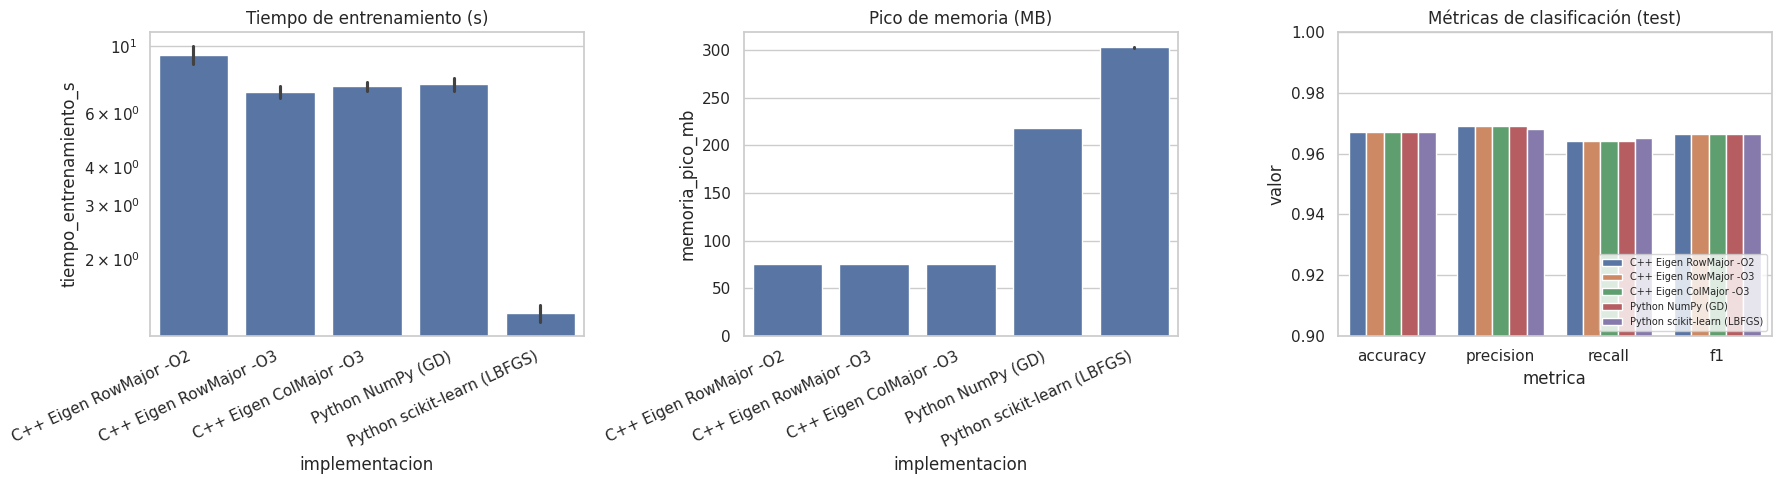

In [ ]:

# Se crean tres gráficos en una misma figura para comparar visualmente
# los resultados de las cinco implementaciones.
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Se establece el orden en el que aparecerán las implementaciones.
orden = list(configs.keys())


# 1. COMPARACIÓN DEL TIEMPO DE ENTRENAMIENTO

# Se genera un gráfico de barras con el tiempo promedio de entrenamiento
# de cada implementación. Las barras de error representan la desviación
# estándar de las tres ejecuciones realizadas.
sns.barplot(
    data=df_res,
    x="implementacion",
    y="tiempo_entrenamiento_s",
    order=orden,
    errorbar="sd",
    ax=ax[0]
)

# Se utiliza una escala logarítmica para facilitar la visualización
# de las diferencias entre los tiempos de entrenamiento.
ax[0].set_yscale("log")
ax[0].set_title("Tiempo de entrenamiento (s)")


# 2. COMPARACIÓN DEL CONSUMO DE MEMORIA

# Se genera un gráfico de barras para comparar el consumo máximo
# de memoria registrado por cada implementación.
sns.barplot(
    data=df_res,
    x="implementacion",
    y="memoria_pico_mb",
    order=orden,
    errorbar="sd",
    ax=ax[1]
)

ax[1].set_title("Pico de memoria (MB)")


# 3. COMPARACIÓN DE LAS MÉTRICAS DE CLASIFICACIÓN

# Se reorganizan los datos para representar las cuatro métricas
# (Accuracy, Precision, Recall y F1-Score) en un mismo gráfico.
met = df_res.melt(
    id_vars="implementacion",
    value_vars=["accuracy", "precision", "recall", "f1"],
    var_name="metrica",
    value_name="valor"
)

# Se genera un gráfico de barras agrupadas para comparar
# las métricas obtenidas por cada implementación.
sns.barplot(
    data=met,
    x="metrica",
    y="valor",
    hue="implementacion",
    hue_order=orden,
    ax=ax[2]
)

# Se ajusta el rango del eje vertical para visualizar mejor
# las diferencias entre las métricas.
ax[2].set_ylim(0.9, 1.0)
ax[2].set_title("Métricas de clasificación (test)")

# Se ubica la leyenda en la parte inferior derecha del gráfico.
ax[2].legend(fontsize=7, loc="lower right")


# 4. AJUSTES DE PRESENTACIÓN

# Se inclinan las etiquetas de los gráficos de tiempo y memoria
# para facilitar su lectura.
for a in ax[:2]:
    a.tick_params(axis="x", rotation=25)
    for lbl in a.get_xticklabels():
        lbl.set_ha("right")

# Se ajusta automáticamente la distribución de los gráficos
# para evitar que los títulos y etiquetas se superpongan.
plt.tight_layout()

# Se muestran los tres gráficos.
plt.show()


Se generaron tres gráficas para comparar los resultados del benchmark. La primera presenta el tiempo de entrenamiento de las cinco implementaciones en escala logarítmica, con barras de error que representan la desviación estándar de las tres ejecuciones; se observa que Scikit-Learn es la más rápida y que las demás implementaciones, todas con gradiente descendente, tienen tiempos similares entre sí. La segunda muestra el pico de memoria: las tres versiones de C++ se mantienen en ≈75 MB, frente a 218 MB de NumPy y 303 MB de Scikit-Learn.

La tercera gráfica compara las métricas de clasificación (con el eje vertical entre 0.90 y 1.00 para visualizar las diferencias pequeñas), cuyos valores son prácticamente idénticos en las cinco implementaciones.

###Análisis de localidad de memoria y optimización del acceso a los datos

In [ ]:
# Se muestran los tamaños de caché de la CPU asignada por Colab (útil para argumentar en el informe).
print(subprocess.run("lscpu | grep -iE 'model name|cache'", shell=True,
                     capture_output=True, text=True).stdout)

# Se ejecuta el micro-benchmark de localidad del programa C++.
loc = ejecutar(["./lr_row_O3", "locality", TRAIN_BIN])
tabla_loc = pd.DataFrame({
    "experimento": ["Recorrido por FILAS (contiguo)", "Recorrido por COLUMNAS (saltos)",
                    "Gradiente en DOS pasadas", "Gradiente FUSIONADO (1 pasada)"],
    "ms_por_iteracion": [loc["loc_filas_ms"], loc["loc_columnas_ms"],
                         loc["loc_dospasadas_ms"], loc["loc_fusionado_ms"]],
})
display(tabla_loc)
print(f"Diferencia máxima entre ambos gradientes (verificación de corrección): {loc['loc_diff_max']:.2e}")
print(f"Localidad espacial : columnas/filas   = {loc['loc_columnas_ms']/loc['loc_filas_ms']:.2f}x más lento")
print(f"Localidad temporal : dos pasadas/fusionado = {loc['loc_dospasadas_ms']/loc['loc_fusionado_ms']:.2f}x")

# Se compara además el efecto del layout de Eigen (RowMajor vs ColMajor) en el entrenamiento completo.
print("\nEigen RowMajor vs ColMajor (entrenamiento completo, s):")
print(resumen.loc[["C++ Eigen RowMajor -O3", "C++ Eigen ColMajor -O3"], "tiempo_entrenamiento_s"])

Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
L1d cache:                               32 KiB (1 instance)
L1i cache:                               32 KiB (1 instance)
L2 cache:                                256 KiB (1 instance)
L3 cache:                                55 MiB (1 instance)



,experimento,ms_por_iteracion
0,Recorrido por FILAS (contiguo),14.414081
1,Recorrido por COLUMNAS (saltos),116.172588
2,Gradiente en DOS pasadas,7.408371
3,Gradiente FUSIONADO (1 pasada),29.794114


Diferencia máxima entre ambos gradientes (verificación de corrección): 1.00e-06
Localidad espacial : columnas/filas   = 8.06x más lento
Localidad temporal : dos pasadas/fusionado = 0.25x

Eigen RowMajor vs ColMajor (entrenamiento completo, s):
implementacion
C++ Eigen RowMajor -O3    7.0698
C++ Eigen ColMajor -O3    7.3678
Name: tiempo_entrenamiento_s, dtype: float64


Se consultaron las cachés de la CPU asignada por Colab (L1d de 32 KiB, L2 de 256 KiB y L3 de 55 MiB) y se ejecutó el micro-benchmark de localidad del programa en C++. En la primera prueba, el recorrido por columnas tardó 8.06 veces más que el recorrido por filas (116.17 ms frente a 14.41 ms). Al recorrer por columnas, los elementos consecutivos están separados por 784 × 4 = 3136 bytes, por lo que cada acceso carga una línea de caché de 64 bytes de la que solo se aprovechan 4. Además, las líneas que deberían reutilizarse entre columnas (≈767 KB) superan la caché L2, de modo que los datos deben volver a pedirse a la L3. Esto evidencia la importancia de la localidad espacial.

En la segunda prueba, el gradiente en dos pasadas tardó 7.41 ms por iteración y el gradiente fusionado 29.79 ms, es decir, 4.0 veces más, a pesar de que la diferencia máxima entre ambos resultados fue de 1.00e-06 (son equivalentes numéricamente). Aunque el método fusionado recorre la matriz una sola vez, su producto punto escrito a mano es escalar y no se vectoriza: una sola pasada ya tarda 14.41 ms, casi el doble de las dos pasadas completas de Eigen, que utiliza instrucciones SIMD y bloqueo. Por tanto, la ganancia teórica en localidad temporal no compensó la pérdida en vectorización, lo que muestra que toda optimización debe validarse con mediciones. Una versión por bloques (procesar unas 256 filas con Eigen) permitiría aprovechar ambas ventajas.

Finalmente, en el entrenamiento completo, RowMajor tardó 7.0698 s y ColMajor 7.3678 s. Esta diferencia (4.0 %) es pequeña y cambió de signo respecto a una ejecución previa, por lo que no es concluyente: en Eigen, los productos Xw y Xᵀerr recorren memoria contigua en ambos órdenes de almacenamiento.

##Conclusiones generales

El desarrollo de este proyecto permitió implementar y comparar cinco versiones de un modelo de regresión logística para clasificar los dígitos 3 y 8 de MNIST: tres en C++ con Eigen, una en NumPy y una con Scikit-Learn. Las cinco alcanzaron un Accuracy de 96.72 %, con Precision, Recall y F1 muy similares, por lo que la calidad de clasificación fue equivalente y las diferencias se encuentran en la eficiencia.

En tiempo de entrenamiento, Scikit-Learn fue el más rápido (1.3286 s) gracias al optimizador L-BFGS, que aprovecha información de curvatura; esa diferencia se debe al algoritmo y no al lenguaje. Entre las implementaciones con gradiente descendente, C++ O3 y NumPy fueron prácticamente equivalentes (1.06x), porque el entrenamiento se reduce a productos matriz-vector con baja intensidad aritmética (0.5 FLOP por byte) y está limitado por el ancho de banda de memoria. La diferencia entre almacenamiento por filas y por columnas no fue concluyente.

En memoria, C++ consumió ≈75 MB frente a 218 MB de NumPy y 303 MB de Scikit-Learn, una vez medidos todos los procesos con el mismo criterio (VmHWM). Ese valor en C++ es explicable por la carga de datos y podría reducirse a la mitad leyendo directamente sobre el almacenamiento de Eigen.

Las pruebas de localidad mostraron que el recorrido por columnas es 8.06 veces más lento que por filas, y que fusionar el gradiente en una sola pasada no mejoró el tiempo por la falta de vectorización. Esto evidencia que las optimizaciones deben evaluarse con pruebas reales. Los tiempos absolutos también varían entre sesiones de Colab, por lo que solo deben compararse mediciones hechas en una misma sesión.

Por tanto, no existe una implementación superior en todos los aspectos: Scikit-Learn ofrece el menor tiempo y la mayor simplicidad, mientras que C++ ofrece el menor consumo de memoria y un control explícito sobre el almacenamiento y el acceso a los datos.

In [ ]:
!lscpu | grep -o 'avx[^ ]*\|fma' | sort -u

avx
avx2
fma


In [ ]:
print(modelo_sk.n_iter_)

[78]
